# **Predicting Customer Term Deposit Subscription Using Classification Models**

## **1. Business Objective**

A Portuguese banking institution launched a direct marketing campaign to promote its term deposit product. The marketing team aims to identify customers who are most likely to subscribe to the product, so the team can prioritize potential customers, optimize campaign targeting, and improve marketing strategy.

To address this objective, this project will develop and compare machine learning classification models to predict the likelihood of a customer subscribing to a term deposit and figure out the best performing-model. The output of the models will be a subscription probability score, and a binary prediction (Yes/No) on each customer in the test dataset.

## **2. Data Understanding**

The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be `yes` or `no` subscribed.

The dataset consists of 41188 observations and 20 inputs, ordered by date from May 2008 to November 2010 with the variables are described as follows:


#### **Bank client data:**
- `age` (numeric)
- `job` : type of job (categorical: "admin.", "unknown", "unemployed","management", "housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", "technician", "services")
- `marital` : marital status (categorical: "married", "divorced", "single"; note: "divorced" means divorced or widowed)
- `education` (categorical: "unknown", "secondary", "primary", "tertiary")
- `default`: has credit in default? (binary: "yes", "no")
- `balance`: average yearly balance, in euros (numeric)
- `housing`: has housing loan? (binary: "yes", "no")
- `loan`: has personal loan? (binary: "yes", "no")

#### **Related with the last contact of the current campaign:**
- `contact`: contact communication type (categorical: "unknown", "telephone", "cellular")
- `day`: last contact day of the month (numeric)
- `month`: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")
- `duration`: last contact duration, in seconds (numeric)

#### **Other attributes:**
- `campaign`: number of contacts performed during this campaign and for this client (numeric, includes last contact)
- `pdays`: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)
- `previous`: number of contacts performed before this campaign and for this client (numeric)
- `poutcome`: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")


#### **Output variable (desired target):**
- `y` has the client subscribed a term deposit? (binary: "yes","no")

*Source:* [Bank Marketing Campaign](https://archive.ics.uci.edu/dataset/222/bank+marketing?utm_source=chatgpt.com)

## **3. Data Loading & Wrangling**
Before loading and processing the dataset, first import all the libraries needed for data manipulation, preprocessing, visualization, and machine learning model development. This project will compare three classification models:

- **Logistic Regression** as the baseline model.
- **Random Forest with class weight balanced** for class imbalance.
- **Random Forest with random oversampling** to increase proportion of the minority class in the training data.

These models will be trained and evaluated to compare their performance in predicting whether a customer will subscribe to a term deposit.

In [84]:
# Import Library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
# Load Portugese Bank Marketing dataset
df = pd.read_csv('bank-additional-full.csv', sep=';')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Dataset Overview
print(f'Data Columns: {df.columns}')
print(f'Data Shape: {df.shape}')
print(f'Missing Values: {df.isna().sum().sum()}')
print(f'Duplicated Rows: {df.duplicated().sum()}')

Data Columns: Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')
Data Shape: (41188, 21)
Missing Values: 0
Duplicated Rows: 12


> Since the dataset contains duplicate records, duplicate rows need to be identified and removed to avoid redundant observations and ensure data consistency before further analysis and model development.

In [5]:
# Drop duplicates
df = df.drop_duplicates()
df.shape

(41176, 21)

In [ ]:
# Generate Descriptive Statistics
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,962.464810,0.173013,0.081922,93.575720,-40.502863,3.621293,5167.034870
std,10.42068,259.305321,2.770318,186.937102,0.494964,1.570883,0.578839,4.627860,1.734437,72.251364
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


## **4. Exploring the Data**

Exploratory Data Analysis (EDA) answers four key questions:

1. **Class balance**: are the two target classes roughly equal? (yes vs. no subscription)
2. **Categorical features**: how many unique values does each categorical column have? This helps determine how many One-Hot Encoding (OHE) columns will be created.
3. **Numerical correlations**: are any numerical features highly correlated with each other? (Multicollinearity can destabilize logistic regression.)
4. **Feature–target relationships**: does all selected features visibly predict customer subscription?

#### **4.1 Class Distribution**

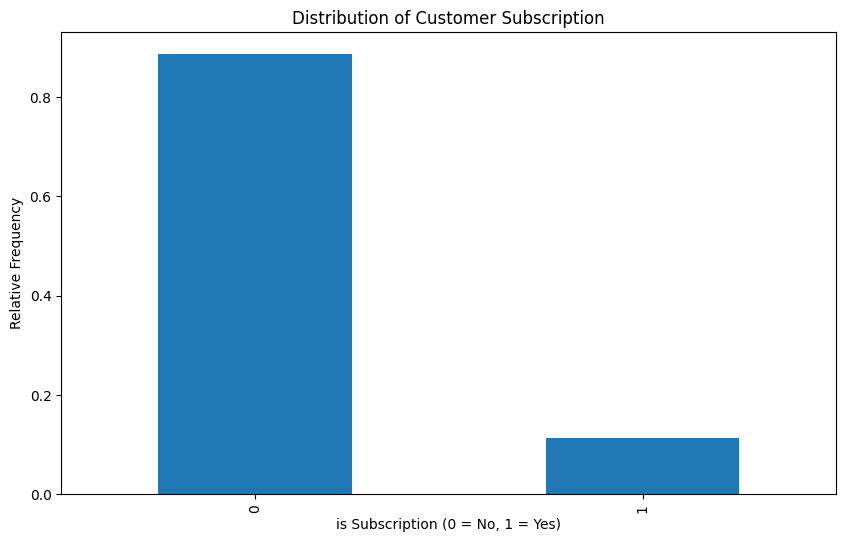

Class Distributin:
y
0    0.887337
1    0.112663
Name: proportion, dtype: float64


In [6]:
# Check class distribution of the target (y)
df['y'] = df["y"].map({"no": 0, "yes": 1})
class_distibution = df['y'].value_counts(normalize=True)

fig, ax = plt.subplots(figsize= (10,6))
class_distibution.plot(kind='bar', ax=ax)
ax.set_xlabel('is Subscription (0 = No, 1 = Yes)')
ax.set_ylabel('Relative Frequency')
ax.set_title('Distribution of Customer Subscription')
plt.show()

print(f'Class Distributin:\n{class_distibution}')

> The target variable is imbalanced, with approximately 88.73% of customers not subscribing to a term deposit (class 0) and only 11.27% subscribing (class 1). This indicates a significant class imbalance, with the majority class (no subscription) considerably outweighing the minority class (subscription).

#### **4.2 Categorical Features**

In [7]:
# Get categorical columns and their unique counts
cat_unique_counts = df.select_dtypes('object').nunique()
print(cat_unique_counts)

job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
dtype: int64


#### **4.3 Numerical Correlation**

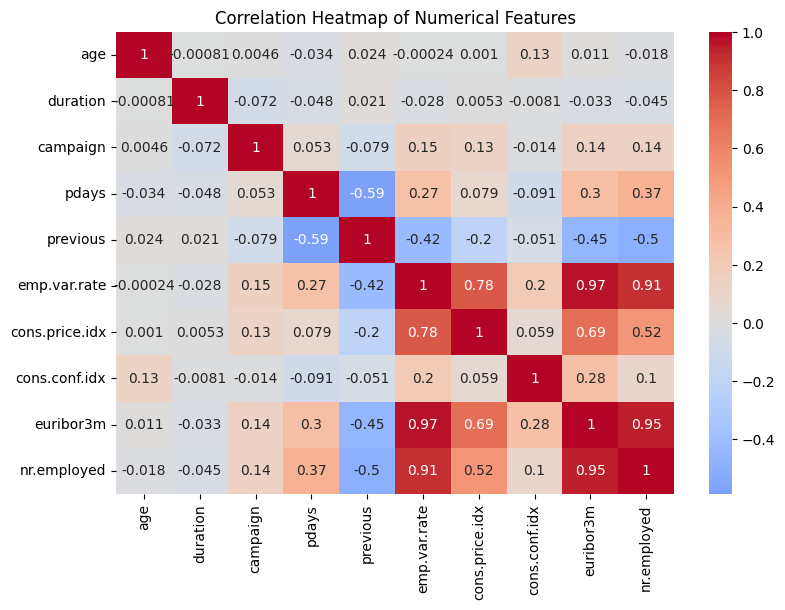

In [8]:
# Create correlation matrix for numerical features
correlation = df.select_dtypes('number').drop(columns=['y']).corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap of Numerical Features')
plt.show()


> Some numerical features (`euribor3m`, `nr.employed`, and `emp.var.rate`) are highly correlated. However, I will will retain these features because this project aims to compare different classification models, and removing correlated features may result in losing potentially useful predictive information.

#### **4.4 Feature vs. Target Relationship**

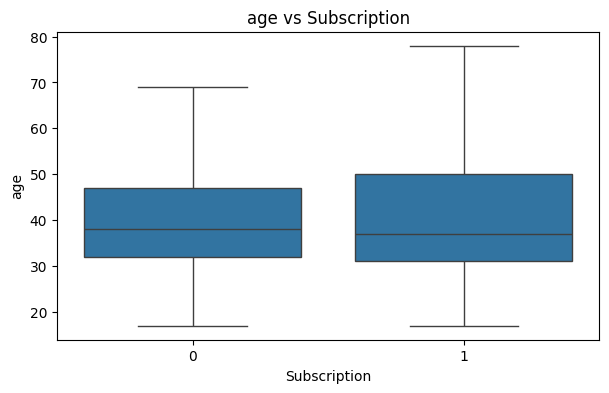

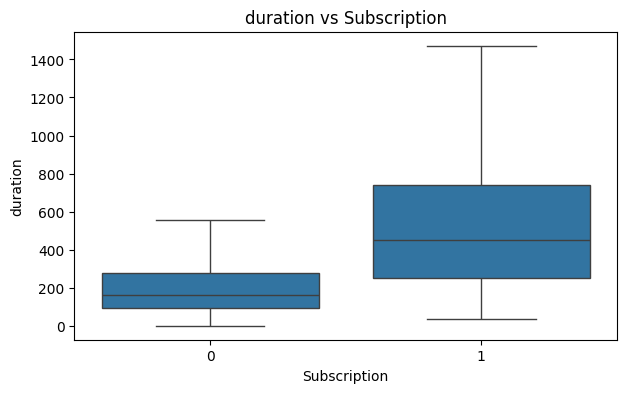

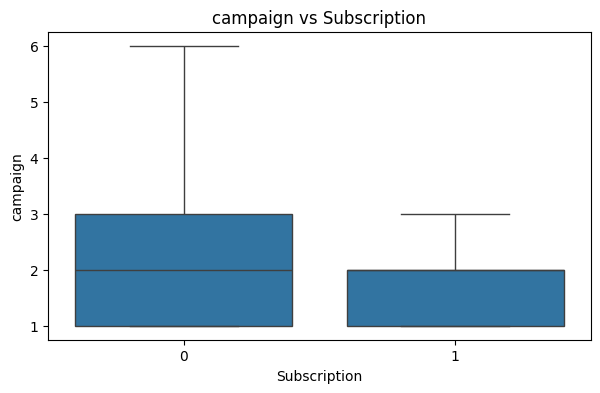

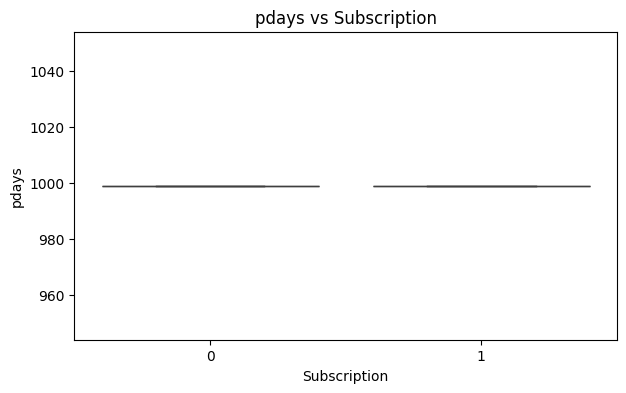

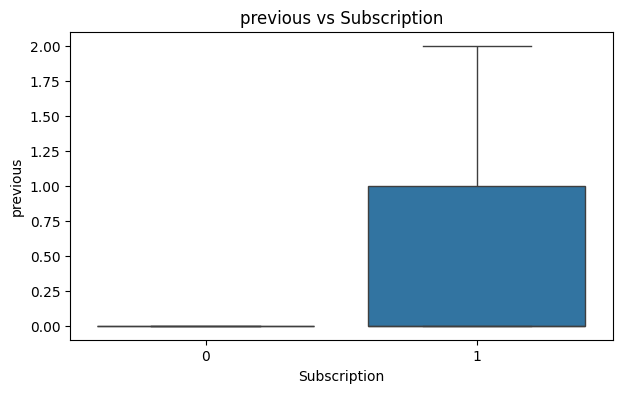

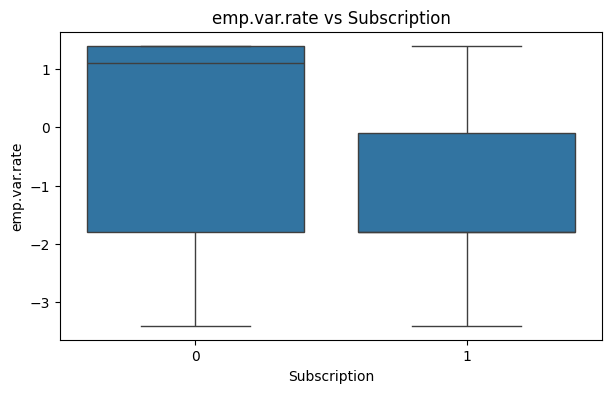

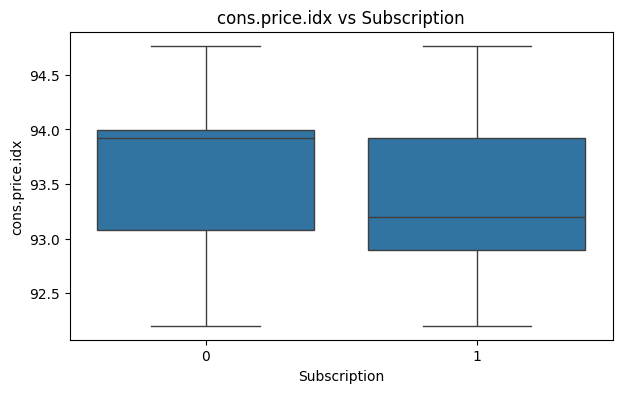

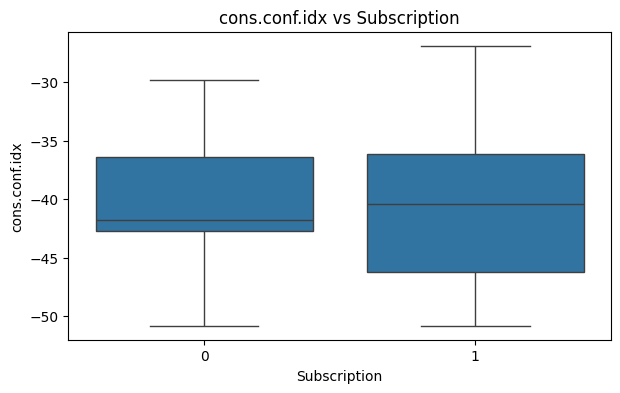

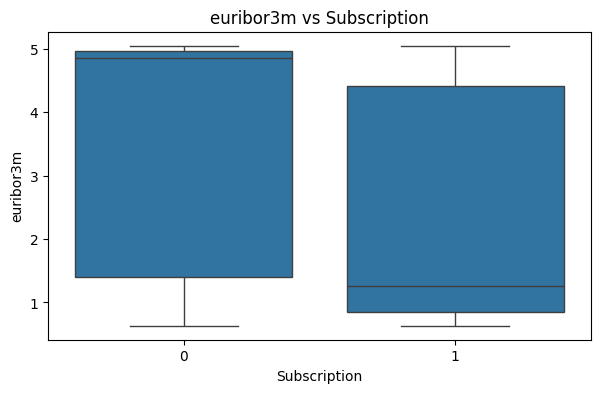

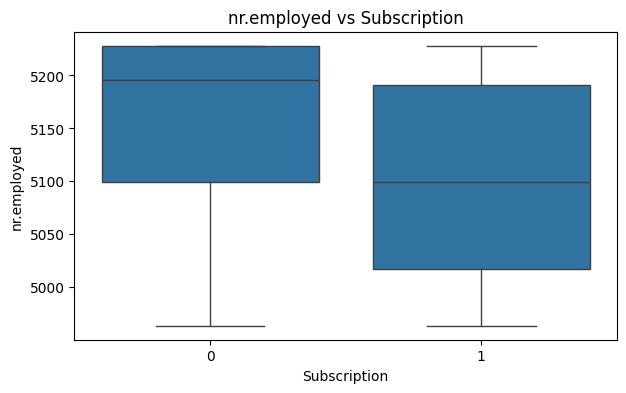

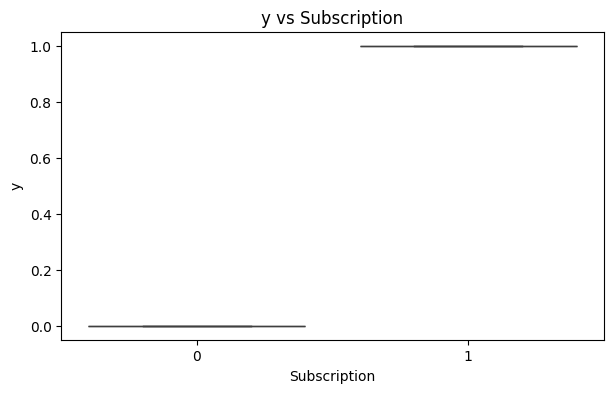

In [9]:
# Numerical features vs. Target
num_features = df.select_dtypes('number').columns
for col in num_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="y",
        y=col,
        showfliers=False
    )

    plt.title(f"{col} vs Subscription")
    plt.xlabel("Subscription")
    plt.ylabel(col)
    plt.show()

> The boxplots provide an initial view of how numerical features differ between customers who subscribed and those who did not. Differences in medians and distributions may indicate potentially useful predictors. Most numerical features, except `age`, `duration`, `pdays`, and `cons.conf.idx`, show highly differences in median values between the two subscription classes. It suggests that these features will likely be useful predictors.


Subscription rate by job:
               subscribed
job                      
blue-collar      0.068951
services         0.081422
entrepreneur     0.085165
housemaid        0.100000
self-employed    0.104856
technician       0.108325
unknown          0.112121
management       0.112175
admin.           0.129667
unemployed       0.142012
retired          0.252619
student          0.314286


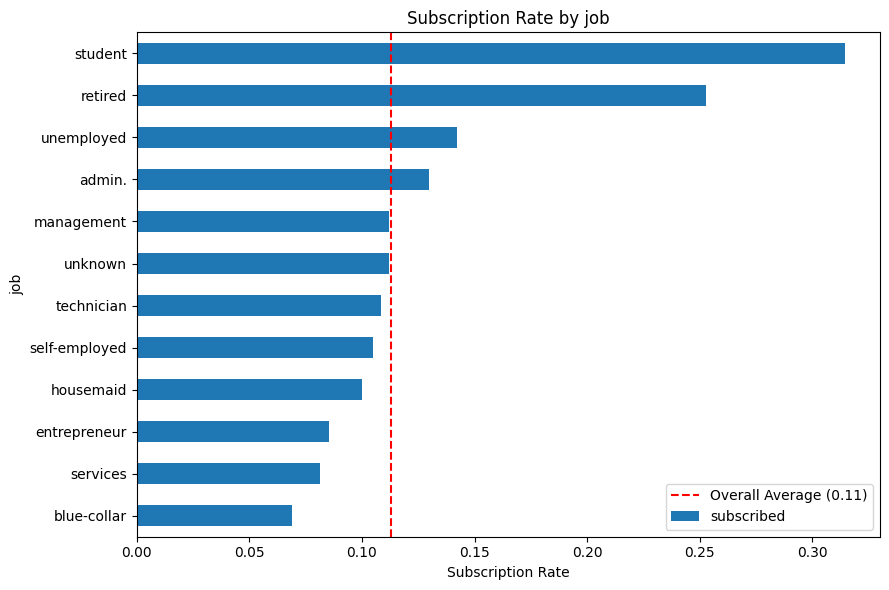


Subscription rate by marital:
          subscribed
marital             
married     0.101561
divorced    0.103231
single      0.140090
unknown     0.150000


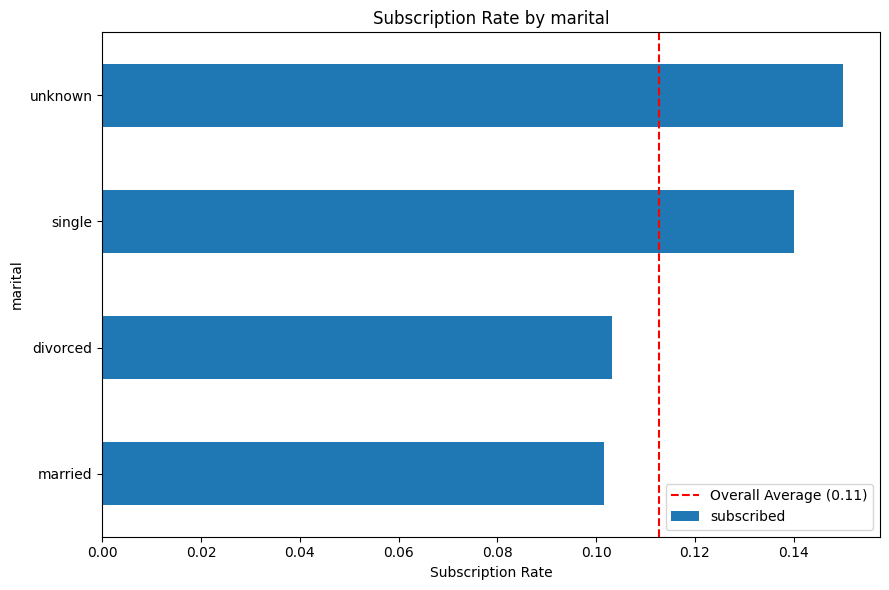


Subscription rate by education:
                     subscribed
education                      
basic.9y               0.078246
basic.6y               0.082060
basic.4y               0.102490
high.school            0.108389
professional.course    0.113550
university.degree      0.137208
unknown                0.145087
illiterate             0.222222


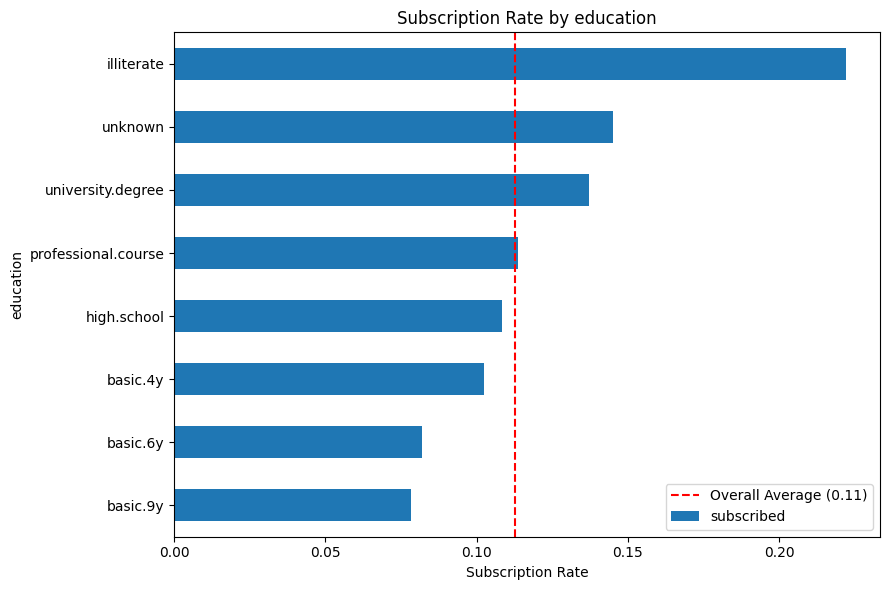


Subscription rate by default:
         subscribed
default            
yes        0.000000
unknown    0.051536
no         0.128803


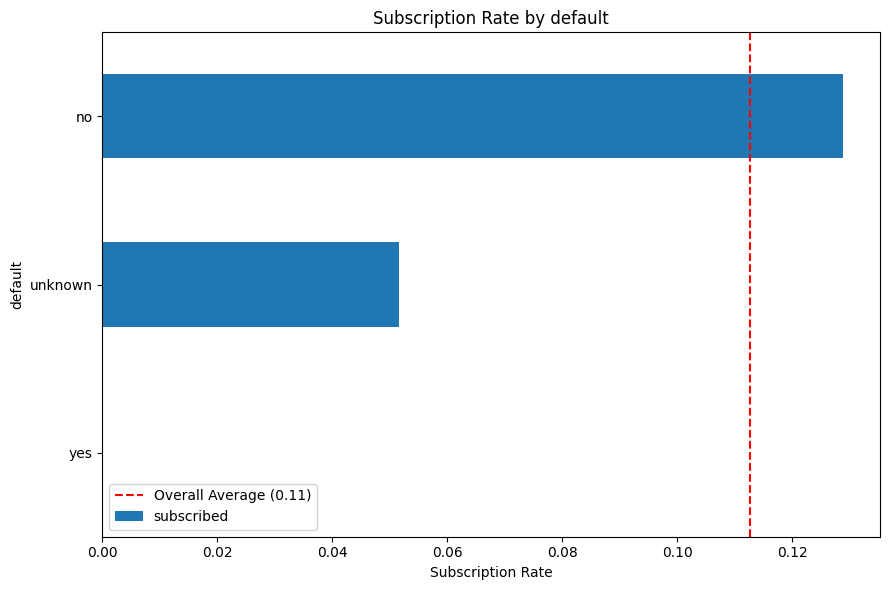


Subscription rate by housing:
         subscribed
housing            
unknown    0.108081
no         0.108783
yes        0.116221


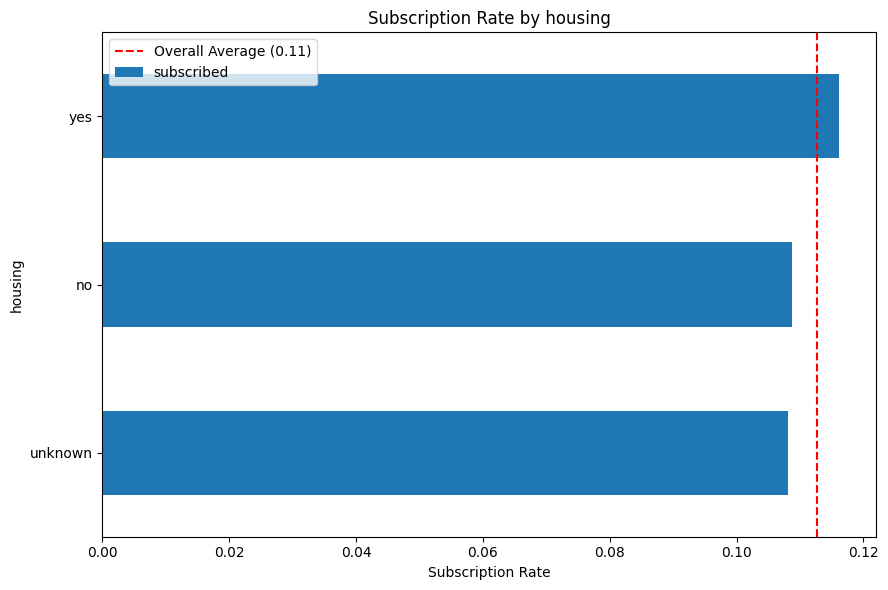


Subscription rate by loan:
         subscribed
loan               
unknown    0.108081
yes        0.109315
no         0.113413


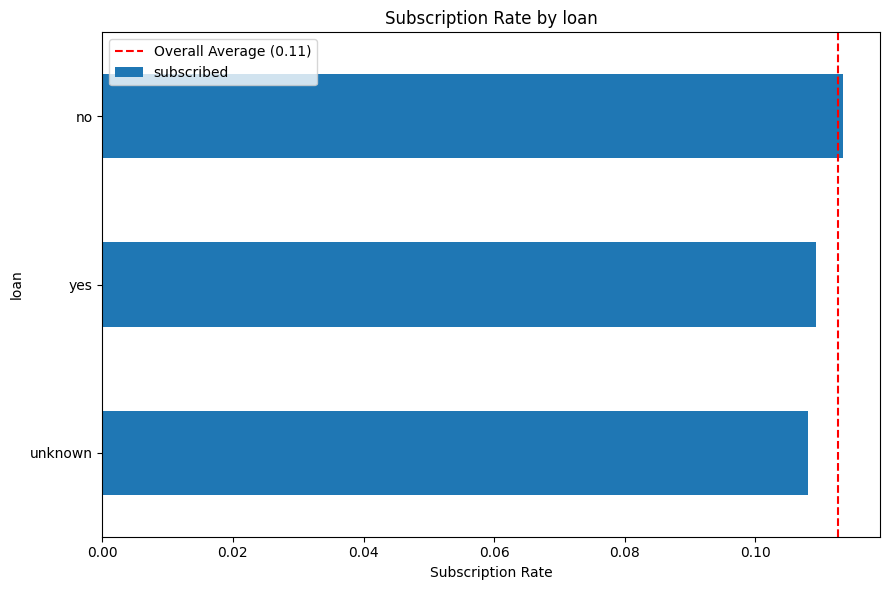


Subscription rate by contact:
           subscribed
contact              
telephone    0.052324
cellular     0.147389


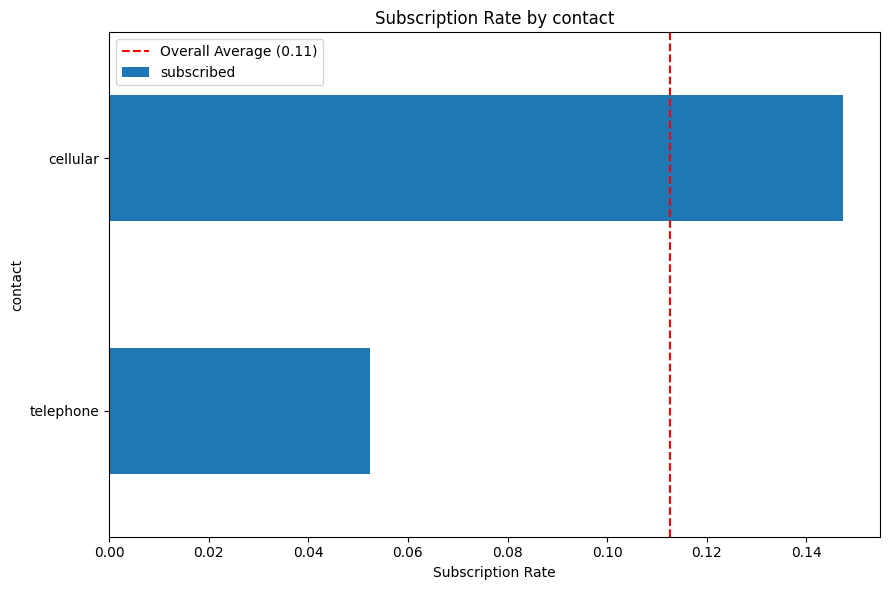


Subscription rate by month:
       subscribed
month            
may      0.064357
jul      0.090389
nov      0.101463
jun      0.105115
aug      0.106056
apr      0.204865
oct      0.439331
sep      0.449123
dec      0.489011
mar      0.505495


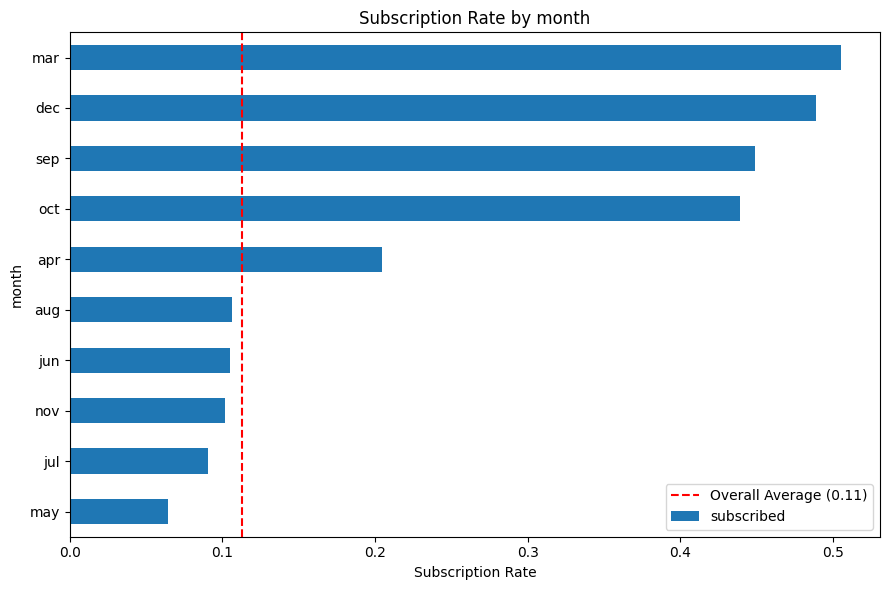


Subscription rate by day_of_week:
             subscribed
day_of_week            
mon            0.099507
fri            0.108101
wed            0.116671
tue            0.117858
thu            0.121142


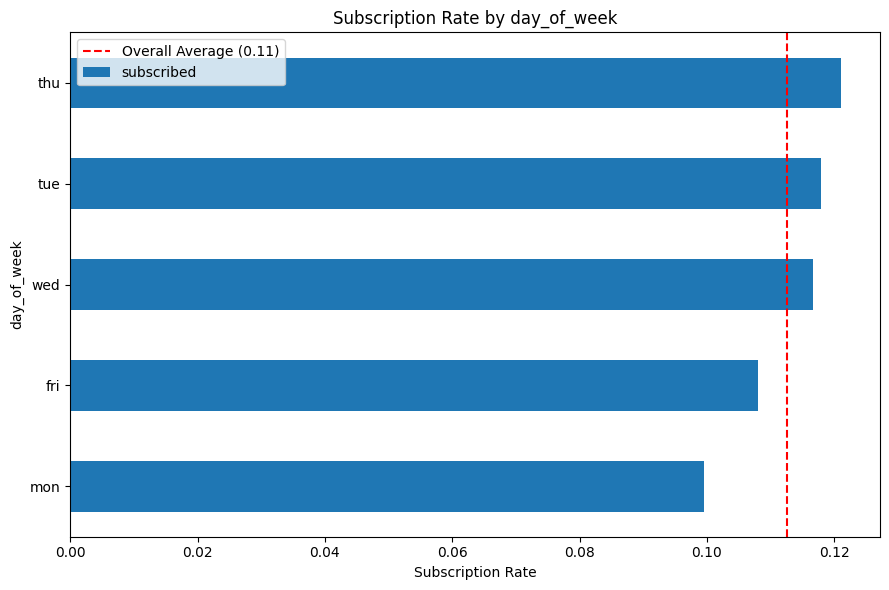


Subscription rate by poutcome:
             subscribed
poutcome               
nonexistent    0.088324
failure        0.142286
success        0.651129


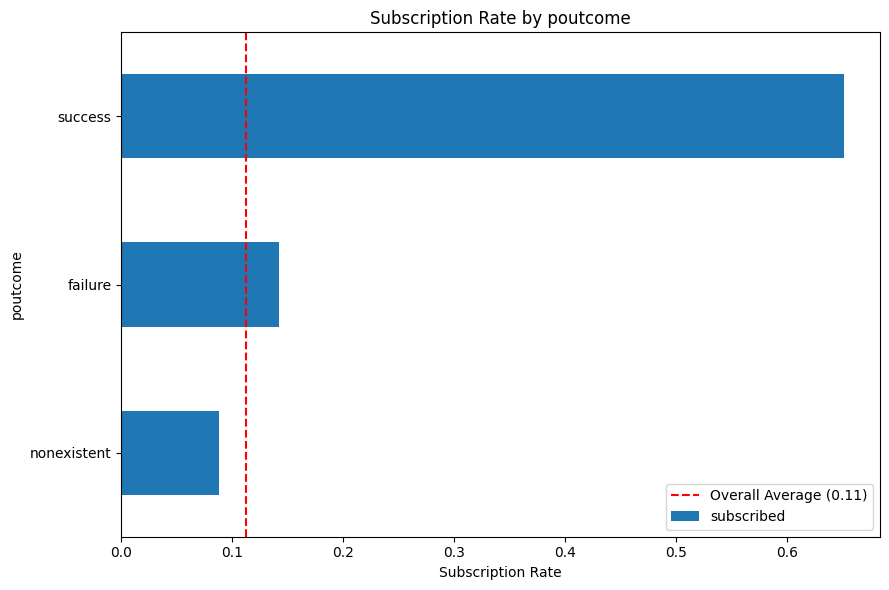

In [10]:
# Categorical features vs. Target


# Calculate overall subscription rate
overall_rate = (df["y"] == 1).mean()

# Identify categorical features
cat_features = df.select_dtypes(include="object").columns

# Loop through each categorical feature
for col in cat_features:

    # Create pivot table
    subscription_rate = pd.pivot_table(
        df.assign(subscribed=(df["y"] == 1).astype(int)),
        values="subscribed",
        index=col,
        aggfunc="mean"
    ).sort_values("subscribed")

    print(f"\nSubscription rate by {col}:")
    print(subscription_rate)

    # Plot horizontal bar chart
    fig, ax = plt.subplots(figsize=(9, 6))

    subscription_rate.plot(
        kind="barh",
        ax=ax,
        legend=False
    )

    ax.set_xlabel("Subscription Rate")
    ax.set_ylabel(col)
    ax.set_title(f"Subscription Rate by {col}")

    # Add overall subscription rate reference line
    ax.axvline(
        x=overall_rate,
        color="red",
        linestyle="--",
        label=f"Overall Average ({overall_rate:.2f})"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

> The charts compare the subscription rate within each category against the overall subscription rate. Categories above the reference line have a higher observed subscription rate, while categories below it have a lower rate.
>
> Subscription rates vary across categories for several categorical features, suggesting that these features may provide useful information for predicting customer subscription.


## **5. Feature Selection**


In [70]:
# Define X as features and y as target
target = 'y'
features = [col for col in df.columns if col not in [target, 'duration']]

X = df[features]
y = df[target]

X.shape, y.shape

((41176, 19), (41176,))

## **6. Train/Test Split (stratified)**
Split `X` and `y` into 80% training and 20% test sets, and use stratification to preserve the same proportion of subscribers and non-subscribers in both sets.

In [71]:
# Split training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
    )



# Second split: create training and validation subsets
X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train, y_train,
    test_size = 0.2,
    random_state = 42,
    stratify=y_train
)

print(f"Training set: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Validation set: X_val {X_val.shape}, y_val {y_val.shape}")
print(f"Test set: X_test {X_test.shape}, y_test {y_test.shape}")

Training set: X_train (32940, 19), y_train (32940,)
Validation set: X_val (6588, 19), y_val (6588,)
Test set: X_test (8236, 19), y_test (8236,)


#### Since the dataset contains both categorical and numerical features, they need to be separated for preprocessing and model training, as each type requires different preprocessing techniques.

In [64]:
# Split categorical and numerical features
cat_features = X.select_dtypes(include='object').columns
num_features = X.select_dtypes(include='number').columns

print("Categorical features:", list(cat_features))
print("Numerical features:", list(num_features))

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


## **7. Model Training**

#### **7.1 Baseline - Logistic Regression**

In [72]:
# Logistic Regression Preprocessing
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("scaler", MinMaxScaler(), num_features)
    ]
)

# Complete pipeline
model_lr = Pipeline(
    steps=[
        ("preprocessor", lr_preprocessor),
        ("model", LogisticRegression(max_iter=1000, solver="lbfgs"))
    ]
)

# Train
model_lr.fit(X_train_fit, y_train_fit)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')),
                                                 ('scaler', MinMaxScaler(),
                                                  Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object'))])),
                ('model', LogisticRegression(max_iter=1000))])

#### **7.2 Random Forest - Class Weight  Balanced**

In [75]:
# Random Forest Class Weight Balanced Preprocessing
rf_preprocessor = ColumnTransformer(
    transformers=[
         ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_features),
         ("numerical", "passthrough", num_features)
    ]
)

rf_balanced = make_pipeline(
    rf_preprocessor,
    RandomForestClassifier(
        class_weight="balanced",
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
)

rf_balanced.fit(X_train_fit, y_train_fit)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')),
                                                 ('numerical', 'passthrough',
                                                  Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object'))])),
                ('randomforestclassifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

#### **7.3 Random Forest - Random Oversampling**

In [74]:
# Random Oversampling Preprocessing
rf_over_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("numerical", "passthrough", num_features)
    ]
)

# Build sklearn pipeline
rf_over = Pipeline(steps=[
    ("preprocessor", rf_over_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Preprocess training data
X_train_processed = rf_over_preprocessor.fit_transform(X_train_fit)

# Oversample training data
X_train_over, y_train_over = RandomOverSampler(
    random_state=42
).fit_resample(X_train_processed, y_train_fit)

# Train Random Forest on oversampled data
rf_over.named_steps["classifier"].fit(
    X_train_over,
    y_train_over
)


RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

## **8. Model Evaluation**

To evaluate and compare the performance of the three classification models, the following metrics are calculate using the same original test set:
- Precision
- Recall
- F1-score
- ROC-AUC

The positive class is defined as 1 (customer subscribed). Predictions are generated using the probability threshold of 0.5, while ROC-AUC is calculated using predicted probabilities.

#### **8.1 Baseline (Logistic Regression) Metrics**

In [76]:
# Generate probabilities and binary predictions at the threshold
y_proba_lr = model_lr.predict_proba(X_val)[:, 1]
y_pred_lr = (y_proba_lr >= 0.5).astype(int)


# Logistic Regression Metrics
lr_metrics = {
    "precision": precision_score(y_val, y_pred_lr, zero_division=0),
    "recall": recall_score(y_val, y_pred_lr, zero_division=0),
    "f1": f1_score(y_val, y_pred_lr, zero_division=0),
    "roc_auc": roc_auc_score(y_val, y_proba_lr)
}
lr_metrics

{'precision': 0.7222222222222222,
 'recall': 0.22776280323450135,
 'f1': 0.3463114754098361,
 'roc_auc': np.float64(0.8047279085014933)}

#### **8.2 Random Forest - Class Weight Balance Metrics**

In [77]:
# Generate probabilities and binary predictions at the threshold
y_proba_rf_balanced = rf_balanced.predict_proba(X_val)[:, 1]
y_pred_rf_balanced = (y_proba_rf_balanced >= 0.5).astype(int)

# Random Forest with class balanced Metrics
rf_balanced_metrics = {
    "precision": precision_score(y_val, y_pred_rf_balanced, zero_division=0),
    "recall": recall_score(y_val, y_pred_rf_balanced, zero_division=0),
    "f1": f1_score(y_val, y_pred_rf_balanced, zero_division=0),
    "roc_auc": roc_auc_score(y_val, y_proba_rf_balanced)
}
rf_balanced_metrics


{'precision': 0.550531914893617,
 'recall': 0.27897574123989216,
 'f1': 0.370304114490161,
 'roc_auc': np.float64(0.7836790055263904)}

#### **8.3 Random Forest - Oversampler Metrics**

In [78]:
# Generate probabilities and binary predictions at the threshold
y_proba_rf_over = rf_over.predict_proba(X_val)[:, 1]
y_pred_rf_over = (y_proba_rf_over >= 0.5).astype(int)


# Random Forest with OverSampler Metrics
rf_over_metrics = {
    "precision": precision_score(y_val, y_pred_rf_over, zero_division=0),
    "recall": recall_score(y_val, y_pred_rf_over, zero_division=0),
    "f1": f1_score(y_val, y_pred_rf_over, zero_division=0),
    "roc_auc": roc_auc_score(y_val, y_proba_rf_over)
}
rf_over_metrics

{'precision': 0.46942148760330576,
 'recall': 0.38274932614555257,
 'f1': 0.4216778025241277,
 'roc_auc': np.float64(0.7790264589882454)}

#### **8.4 Comparing All Model Metrics**

In [79]:
# build a comparison table across models using the same metric keys
compare = pd.DataFrame(
    [
        {"model": "LogReg baseline", **lr_metrics},
        {"model": "RF (class_weight=balanced)", **rf_balanced_metrics},
        {"model": "RF (RandomOverSampler)", **rf_over_metrics},
    ]
).set_index("model")

# display the comparison table
compare

,precision,recall,f1,roc_auc
model,,,,
LogReg baseline,0.722222,0.227763,0.346311,0.804728
RF (class_weight=balanced),0.550532,0.278976,0.370304,0.783679
RF (RandomOverSampler),0.469421,0.382749,0.421678,0.779026


In [85]:
# Predict subscription probabilities
y_proba_test = rf_over.predict_proba(X_test)[:, 1]

# Generate binary predictions
y_pred_test = (y_proba_test >= 0.5).astype(int)


print("Final Test Performance")
print("----------------------")

print("Precision:", precision_score(y_test, y_pred_test))
print("Recall:", recall_score(y_test, y_pred_test))
print("F1-score:", f1_score(y_test, y_pred_test))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_test))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=["No", "Yes"]
))

Final Test Performance
----------------------
Precision: 0.48633879781420764
Recall: 0.38362068965517243
F1-score: 0.42891566265060244
ROC-AUC: 0.7837822096238417

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.95      0.94      7308
         Yes       0.49      0.38      0.43       928

    accuracy                           0.88      8236
   macro avg       0.71      0.67      0.68      8236
weighted avg       0.87      0.88      0.88      8236



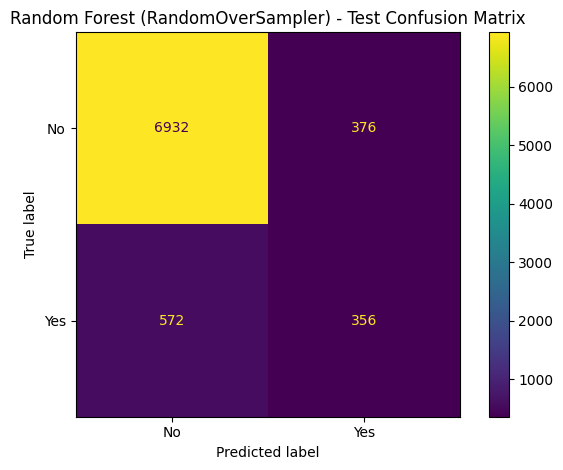

In [89]:
# plot the confusion matrix to see TP/FP/TN/FN of the best model (Random Forest with OverSampler)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=["No", "Yes"],
    values_format="d"
)

plt.title("Random Forest (RandomOverSampler) - Test Confusion Matrix")
plt.tight_layout()
plt.show()

## **9. Model Interpretation**
The models were evaluated using Precision, Recall, F1-score, and ROC-AUC with the following validation results:

1. Logistic Regression (Baseline): Achieves the highest precision (72.2%) and ROC-AUC (80.5%), indicating more reliable positive predictions and better overall class discrimination. However, its low recall (22.8%) means it misses most potential customers who would subscribe.

2. Random Forest (Class Weight = Balanced): Improves recall from 22.8% to 27.9% compared to the baseline, but with lower precision (55.1%). This indicates better detection of potential subscribers at the cost of more false positive predictions.

3. Random Forest (RandomOverSampler): Achieves the highest recall (38.3%) and F1-score (42.2%), indicating the best balance between precision and recall among the three models. However, its lower precision (46.9%) means more false positive predictions.

**Overall**: Random Forest with RandomOverSampler is the most promising model for identifying potential subscribers as it has the highest validation F1-score, supported by its highest recall among the evaluated models.

**Final Test Evaluation: Confusion Matrix**
The confusion matrix of the best performance model (Random Forest with Over Sampler) shows the following results:
- **True Positive (356)**: Successfully identifies 356 customers who subscribe to the term deposit.
- **False Positive (376)**: Incorrectly predicts 376 non-subscribers as potential subscribers, which may lead to unnecessary marketing efforts.
- **False Negative (572)**: Fails to identify 572 actual subscribers, representing potential missed opportunities.
- **True Negative (6,932)**: Correctly identifies 6,932 customers who do not subscribe.

Overall, the confusion matrix indicates that the model correctly identifies a substantial number of non-subscribers but still misses some potential subscribers. This suggests an opportunity to improve the model's ability to identify actual subscribers while managing false positive predictions.

#### **9.1 Prediction Output**
Using RandomForest OverSampler Model as the best-performing model to generate the binary prediction output.

In [90]:
# Set classification threshold
THRESHOLD = 0.50

# Generate subscription probabilities
y_proba_test = rf_over.predict_proba(X_test)[:, 1]

# Generate binary predictions
y_pred_test = (y_proba_test >= THRESHOLD).astype(int)

# Create prediction output
prediction_output = X_test.copy()

prediction_output["subscription_probability"] = y_proba_test
prediction_output["predicted_subscription"] = np.where(
    y_pred_test == 1, "Yes", "No"
)

# Add actual subscription status for evaluation
prediction_output["actual_subscription"] = y_test.map({
    0: "No",
    1: "Yes"
})

# Display results
prediction_output.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscription_probability,predicted_subscription,actual_subscription
8490,35,services,married,high.school,unknown,no,no,telephone,jun,wed,...,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,0.036667,No,No
40844,30,student,single,professional.course,no,yes,no,cellular,sep,tue,...,1,success,-1.1,94.199,-37.5,0.880,4963.6,0.819667,Yes,Yes
35681,37,self-employed,single,basic.4y,no,yes,no,cellular,may,mon,...,1,failure,-1.8,92.893,-46.2,1.244,5099.1,0.286667,No,No
35994,31,blue-collar,single,professional.course,no,no,no,cellular,may,tue,...,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1,0.275238,No,No
21961,31,technician,married,university.degree,no,unknown,unknown,cellular,aug,wed,...,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,0.240000,No,No
11522,52,blue-collar,married,basic.9y,no,no,no,telephone,jun,fri,...,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,0.046667,No,No
35058,48,blue-collar,married,basic.9y,no,no,no,cellular,may,fri,...,0,nonexistent,-1.8,92.893,-46.2,1.250,5099.1,0.060000,No,No
31093,46,admin.,married,high.school,unknown,yes,no,cellular,may,wed,...,1,failure,-1.8,92.893,-46.2,1.334,5099.1,0.030000,No,No
32880,35,services,divorced,university.degree,no,yes,no,cellular,may,mon,...,0,nonexistent,-1.8,92.893,-46.2,1.299,5099.1,0.030000,No,No
22655,58,technician,divorced,professional.course,no,no,no,cellular,aug,fri,...,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,0.133333,No,No


## **10. Summary**

This project developed three classification models to predict whether a bank customer subscribes to a term deposit: Logistic Regression, Random Forest with class weighting, and Random Forest with RandomOverSampler. The dataset has an imbalanced target distribution, with substantially fewer subscribers than non-subscribers.

Based on the validation results, Random Forest with RandomOverSampler was selected as the best-performing model, achieving the highest recall (38.3%) and F1-score (42.2%) among the three models. In the final test evaluation, the model achieved a precision of 48.6%, recall of 38.4%, and F1-score of 42.9%. Its confusion matrix shows that the model correctly identified 356 subscribers and 6,932 non-subscribers, while generating 376 false positives and missing 572 actual subscribers.

Based on these findings, the bank could use the model's predicted subscription probabilities to prioritize potential subscribers for targeted marketing campaigns. However, its relatively low recall indicates that a considerable number of potential subscribers remain unidentified. Further improvements could help improve prediction performance and balance the trade-off between identifying potential subscribers and minimizing unnecessary marketing efforts.